# Практическое задание №2

## Задание
Используйте файл с информацией о ноутбуках `laptops_na.csv`.

[Источник данных](https://www.kaggle.com/datasets/bhavikjikadara/brand-laptops-dataset)


В нём содержаться следующие переменные:

- `brand`: Название бренда ноутбука.
- `Model`: Конкретная модель или серия ноутбука.
- `Price`: Цена ноутбука в индийских рупиях.
- `Rating`: Рейтинг, присвоенный ноутбуку на основе его характеристик.
- `processor_brand`: Марка процессора, используемого в ноутбуке.
- `processor_tier`: Уровень производительности или категория процессора.
- `num_cores`: Количество вычислительных ядер в процессоре.
- `num_threads`: Количество потоков, поддерживаемых процессором.
- `ram_memory`: Объем оперативной памяти, используемый в ноутбуке.
- `primary_storage_type`: Тип основного хранилища (например, HDD, SSD).
- `primary_storage -apacity`: Емкость основного хранилища ноутбука.
- `secondary_storage_type`: Тип вторичного хранилища, если оно доступно.
- `secondary_storage_capacity`: Емкость вторичного хранилища ноутбука.
- `gpu_brand`: Марка графического процессора (GPU).
- `gpu_type`: Тип графического процессора.
- `is_touch_screen`: Указывает, оснащен ли ноутбук функцией сенсорного экрана.
- `display_size`: Размер дисплея ноутбука в дюймах.
- `resolution_width`: Разрешение по ширине дисплея.
- `resolution_height`: Разрешение дисплея по высоте.
- `OS`: Установленная на ноутбуке операционная система.
- `year_of_warranty`: Срок гарантии, предоставляемой на ноутбук, обычно в годах.

Обратите внимание, что все пункты задания должны сопровождаться _выполненным_ фрагментом кода!

### Задание 1. Проверка отличия распределения от «нормального»

Проанализируйте распределение значений 5-ти любых метрических переменных. Проведите тест для проверки того отличается ли распределение значений переменных от нормального распределения. Сформулируйте гипотезы и выводы по результатам анализа. Постройте гистограммы распределения с наложенной кривой нормального распределения. 

**H0**: распределение значений переменной не отличается от нормального

**H1**: распределение значений переменной отличается от нормального

**Какой тест и почему.** Использую тест **Шпиро-Уилка**, он хорош для малых и средних выборок. (n < 2000)

**Дополнительно:**

- тест **Колмогорова-Смирнова с поправкой Лиллиефорса**. Обычный KS сравнивает данные с нормальным распределением с заранее известными средним и стандартным отклонением. А мы оцениваем их по самой выборке - поэтому поправка Лиллиефорса сделает тест более точным.

- **Q-Q plots** - если распредление нормальное, точки лежат на прямой


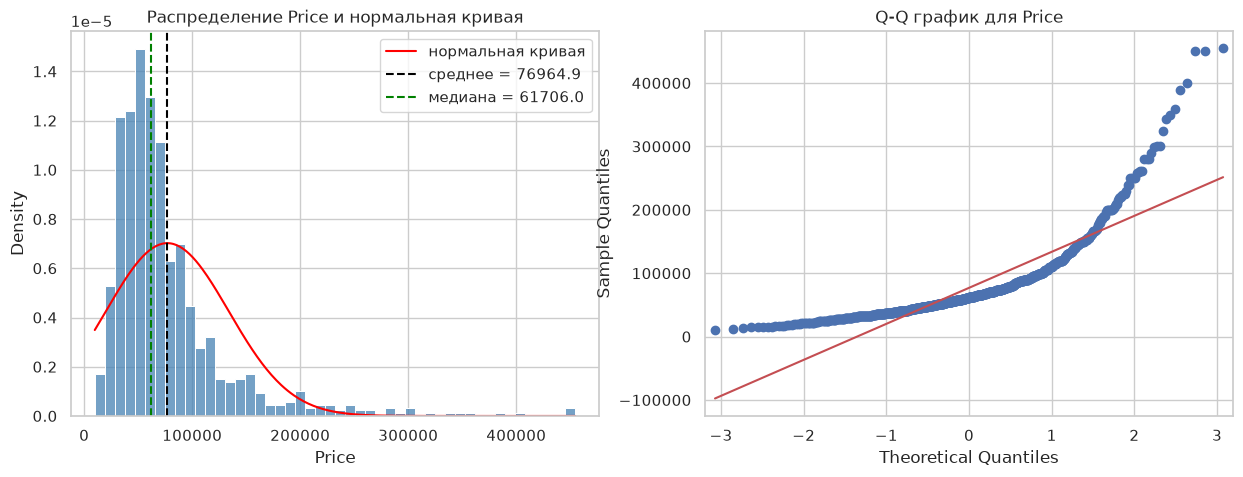

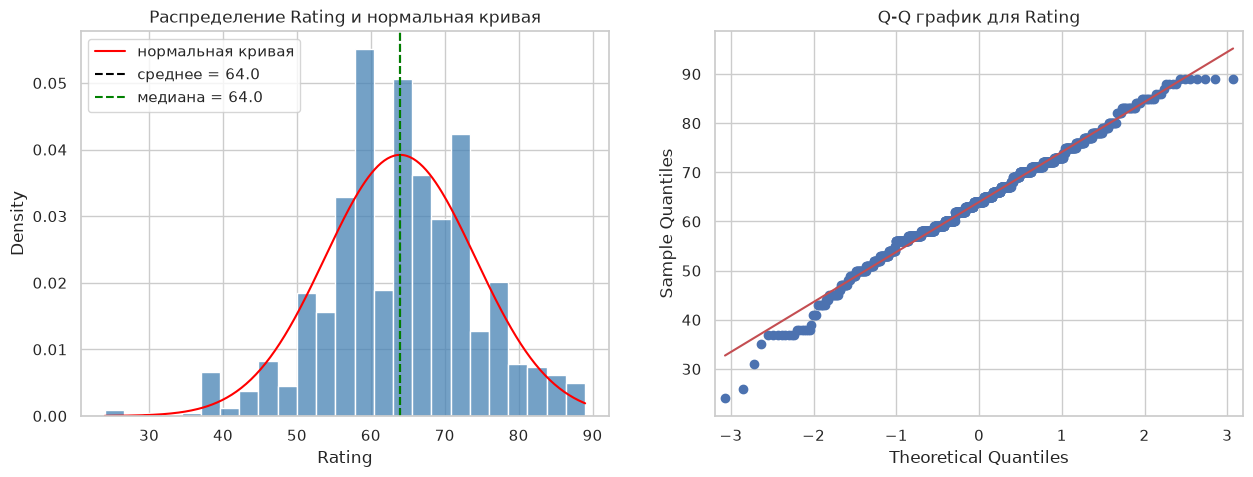

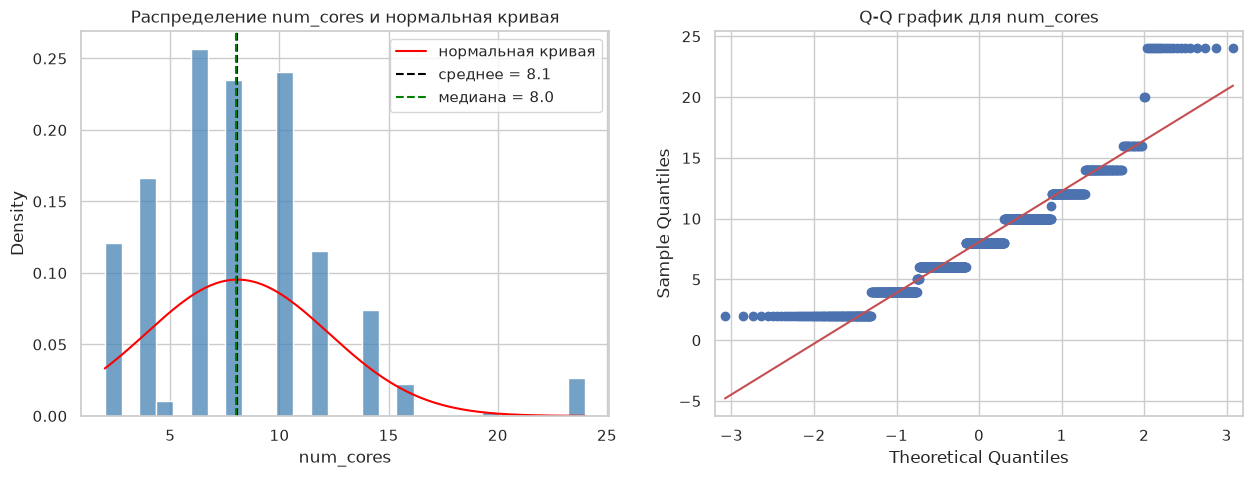

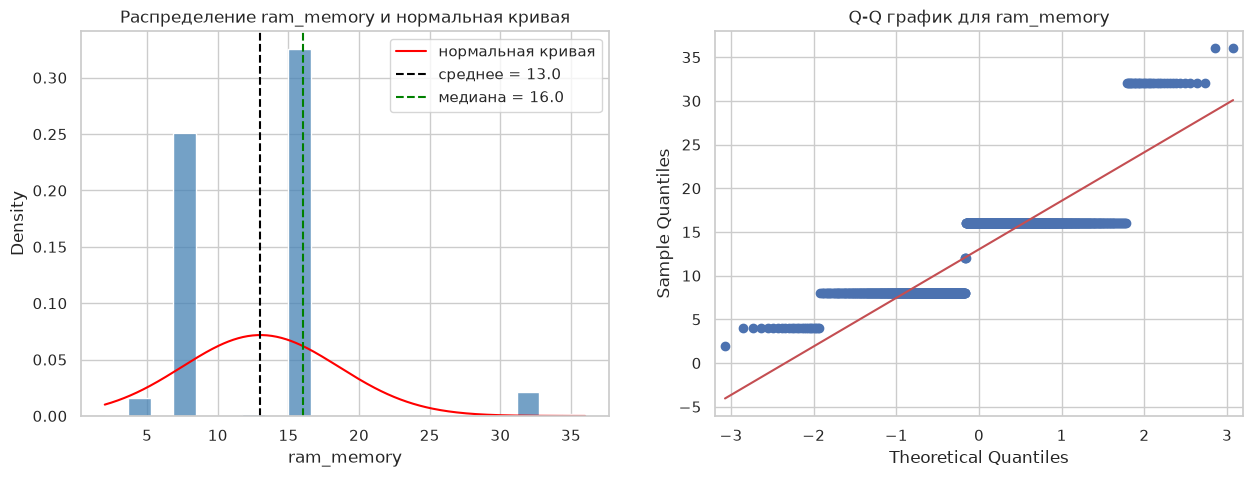

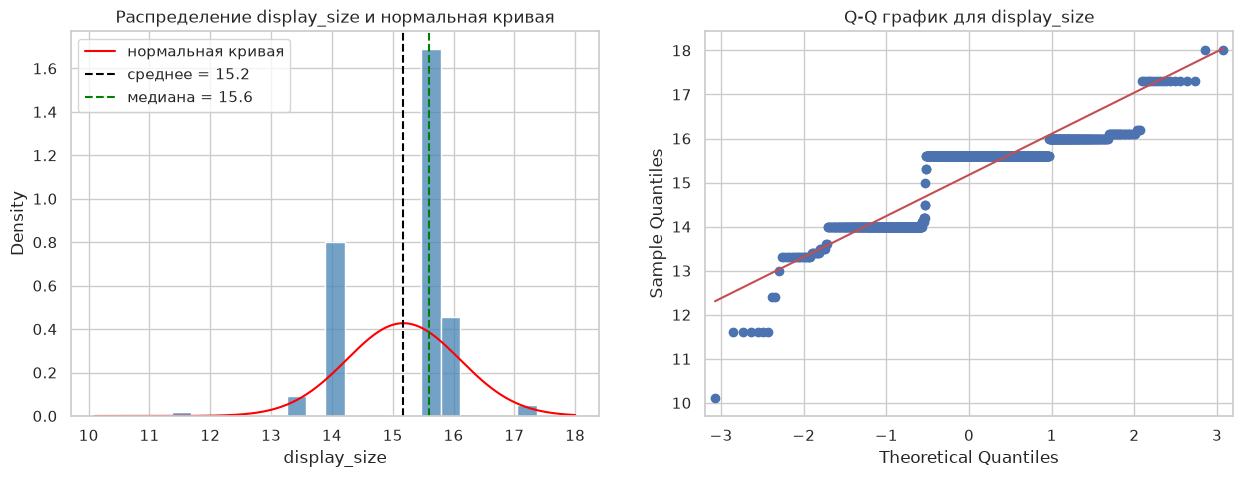

,n,ks_stat,p_value(KS),sw_stat,p_value(SW),H0(SW),H0(KS)
переменная,,,,,,,
Price,942,0.180259,0.001,0.737444,4.343223e-36,отвергается,отвергается
Rating,936,0.060922,0.001,0.990934,1.609501e-05,отвергается,отвергается
num_cores,958,0.131799,0.001,0.905473,6.951565e-24,отвергается,отвергается
ram_memory,942,0.267931,0.001,0.723824,8.965061e-37,отвергается,отвергается
display_size,943,0.374237,0.001,0.783026,1.398311e-33,отвергается,отвергается


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.graphics.gofplots import qqplot

sns.set_theme(style="whitegrid")

df = pd.read_csv("laptops_na.csv")

vars = ["Price", "Rating", "num_cores", "ram_memory", "display_size"] 
results = []

alpha = 0.05

for var in vars:
    x = df[var].dropna()

    mu = x.mean()
    sigma = x.std()

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    sns.histplot(data= x, bins ='auto', stat='density', ax=axes[0], color='steelblue')
    xs = np.linspace(x.min(), x.max(), 300)
    axes[0].plot(xs, stats.norm.pdf(xs, mu, sigma), color='red', label="нормальная кривая")
    axes[0].axvline(x=mu, color='black', ls='--', label= f"среднее = {mu:.1f}")
    axes[0].axvline(x=x.median(), color='green', ls='--', label= f"медиана = {x.median():.1f}")
    axes[0].set_title(f"Распределение {var} и нормальная кривая")
    axes[0].legend()

    qqplot(x,line="s", ax=axes[1])
    axes[1].set_title(f"Q-Q график для {var}")
    plt.show()

    # Одновыборочный KS с поправкой Лиллиефорса
    # И тест Шапиро-Уилка

    ks_stat , p_lil = lilliefors(x)
    sw_stat, p_sw = stats.shapiro(x)

    results.append({"переменная": var, "n":len(x), "ks_stat":ks_stat, "p_value(KS)":p_lil,
        "sw_stat":sw_stat, "p_value(SW)":p_sw, "H0(SW)":"отвергается" if p_sw < alpha else "не отвергается", "H0(KS)":"отвергается" if p_lil < alpha else "не отвергается"       
    })

res1 = pd.DataFrame(results).set_index("переменная")
res1

**Выводы**
Для всех 5 переменных оба теста дают p-value < 0.05 => H0 отвергается для всех пяти переменных: их распределения статистически значимо отличаются от нормального. Это подтверждают и графики:

- **Price** - правосторонняя асиметрия, среднее значительно больше медианы. На Q-Q графике заметно не совпадении прямой нормального распредления и точек Price.

- **Rating** - ближе всех к нормальному распредлению. Гистограмма похожа на график нр, на Q-Q графике не совпадения только на концах, более того sw_stat = 0.99 что довольно близко к 1 и означает что это почти нормальное распределение, однако этого не хватает.

- **num_cores**, **ram_memory** и **display_size** - дискретные переменные: принимают несколько значений. Нормальное распределение непрерывно, поэтому такие переменные в принципе не могут быть нормальными - на Q-Q графике видны ступени.

### Задание 2. Тест Хи-квадрат

Проведите тест Хи-квадрат не менее, чем с двумя парами переменных, для которых он применим. Можно использовать как исходные переменные, так и перекодировать их. Постройте для выбранных пар переменных таблицы сопряженности и прокомментируйте их. Сформулируйте гипотезы. Интерпретируйте результаты анализа. Обоснуйте свои выводы. Визуализируйте наблюдаемые тенденции на подходящих графиках.

**H0**: переменные независимы

**H1**: переменные связаны 

**Условие применимости:** во всех клетках **ожидаемые** частоты должны быть ≥ 5 (иначе тест врёт). Поэтому редкие категории (Apple, мелкие бренды) мы выкидываем.

**Что добавлено сверх задания:**
- **V Крамера** — *сила* связи от 0 до 1. Сам χ² отвечает только «есть связь или нет», а на большой выборке «есть» может оказаться и у совсем крошечной связи. Ориентир: < 0.1 — очень слабая, 0.1–0.3 — слабая, 0.3–0.5 — средняя, > 0.5 — сильная.
- **Остатки** = (наблюдаемое − ожидаемое) / √ожидаемое для каждой клетки. Показывают, *где именно* связь: положительный остаток — в этой клетке больше, чем ожидалось; отрицательный — меньше. Если |остаток| > 2, отклонение в клетке существенное.
- Для таблицы 2×2 — **точный тест Фишера** как проверка.

### Пара 1. processor_band & gpu_type
Берем только intel/amd так как у apple/other маленькая выборка, аналогично убираем apple из gpu_type

- **H0** тип видеокарты не зависит от бренда процессора
- **H1** тип видеокарты связан с брендом процессора

In [3]:
print(df.groupby('processor_brand').count()['brand'], '\n')
print(df.groupby('gpu_type').count()['brand'])

processor_brand
amd      235
apple     13
intel    632
other      4
Name: brand, dtype: int64 

gpu_type
apple          14
dedicated     317
integrated    567
Name: brand, dtype: int64


Наблюдаемые количества:
gpu_type         dedicated  integrated
processor_brand                       
amd                    101         134
intel                  217         417

Доли в строке:
gpu_type         dedicated  integrated
processor_brand                       
amd                  42.98       57.02
intel                34.23       65.77

Ожидаемые количества:
gpu_type         dedicated  integrated
processor_brand                       
amd                   86.0       149.0
intel                232.0       402.0

x² = 5.29, p-value = 0.0215
H0 отвергается -> связь есть

V Крамера = 0.078
Очень слабая связь

Тест Фишера: p-value = 0.0214


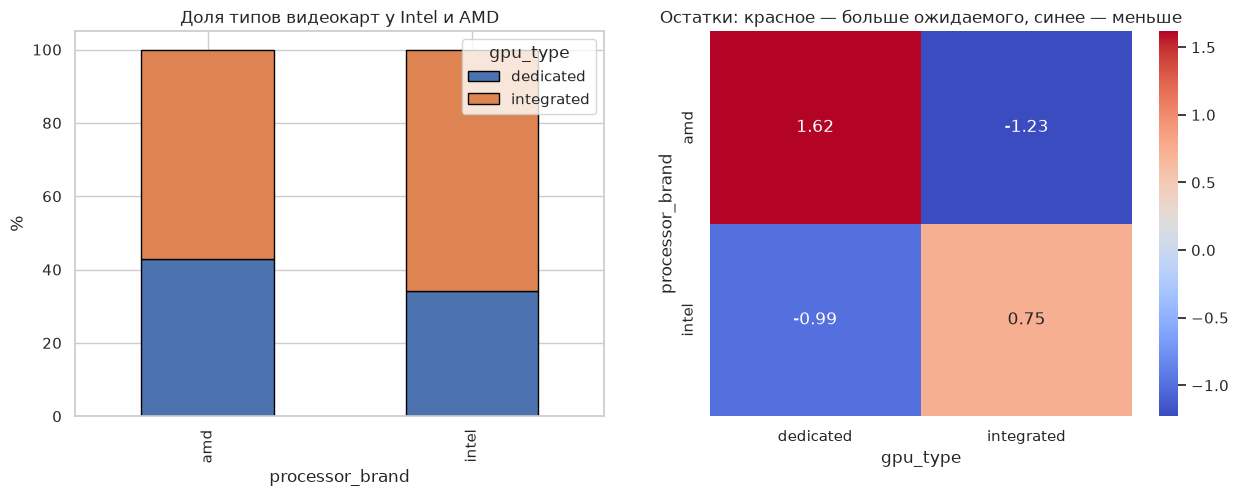

In [4]:

d1 = df[df["processor_brand"].isin(["intel", "amd"]) & df["gpu_type"].isin(["integrated", "dedicated"])]

table1 = pd.crosstab(d1["processor_brand"], d1["gpu_type"])
print('Наблюдаемые количества:')
print(table1)

shares1 = pd.crosstab(d1["processor_brand"], d1["gpu_type"], normalize='index') * 100
print('\nДоли в строке:')
print(shares1.round(2))

chi2, p, _, expected = stats.chi2_contingency(table1)
expected1 = pd.DataFrame(expected, index=table1.index, columns=table1.columns)
print("\nОжидаемые количества:")
print(expected1.round(2))

print(f"\nx² = {chi2:.2f}, p-value = {p:.4f}")
print("H0 отвергается -> связь есть" if p < alpha else "H0 не отвергается -> связи не обнаружено")

n = table1.values.sum()
v1 = np.sqrt(chi2 / (n * (min(table1.shape) - 1)))
print(f"\nV Крамера = {v1:.3f}")
if v1 < 0.1: 
    print("Очень слабая связь")
elif v1 >= 0.1 and v1 < 0.3: 
    print("Слабая связь")
elif v1 >= 0.3 and v1 < 0.5:
    print("Средняя связь")
else:
    print("Сильная связь")

odd, p_fisher = stats.fisher_exact(table1)
print(f"\nТест Фишера: p-value = {p_fisher:.4f}")

resid1 = (table1 - expected1) / np.sqrt(expected1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
shares1.plot(kind="bar", stacked=True, ax=axes[0], edgecolor="black")
axes[0].set_ylabel("%")
axes[0].set_title("Доля типов видеокарт у Intel и AMD")
sns.heatmap(resid1, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Остатки: красное — больше ожидаемого, синее — меньше")

plt.show()

- У ноутбуков на AMD дискретная видеокарта в 43% случаев, а у Intel в 34%
- p-value = 0.02 < 0.05 => H0 отвергается: связь статистически значима.
- Однако V Крамера = 0.078 а значит связь очень слабая.
- Возможное объяснение: процессоры AMD Ryzen популярны в недорогих игровых ноутбуках, где ставят дискретную видеокарту.

### Пара 2. is_touch_screen & ценовая категория

- **H0** наличие сенсорного экрана не свзяано с ценовой категорией
- **H1** наличие сенсорного экрана связано с ценовой категорией

Границы категорий:
               min       max  count
price_cat                          
дешёвые     9800.0   49775.0    314
средние    49990.0   75533.0    314
дорогие    75990.0  454490.0    314

Наблюдаемые количества:
price_cat        дешёвые  средние  дорогие
is_touch_screen                           
False                296      282      239
True                   7       19       55

Доли внутри строки:
price_cat        дешёвые  средние  дорогие
is_touch_screen                           
False              36.23    34.52    29.25
True                8.64    23.46    67.90

Ожидаемые количества:
price_cat        дешёвые  средние  дорогие
is_touch_screen                           
False              275.7    273.8    267.5
True                27.3     27.2     26.5
Минимальная ожидаемая частота: 26.5

x² = 52.93, p-value = 3.204e-12
 H0 отвергается -> связь есть

V Крамера = 0.078
Слабая связь


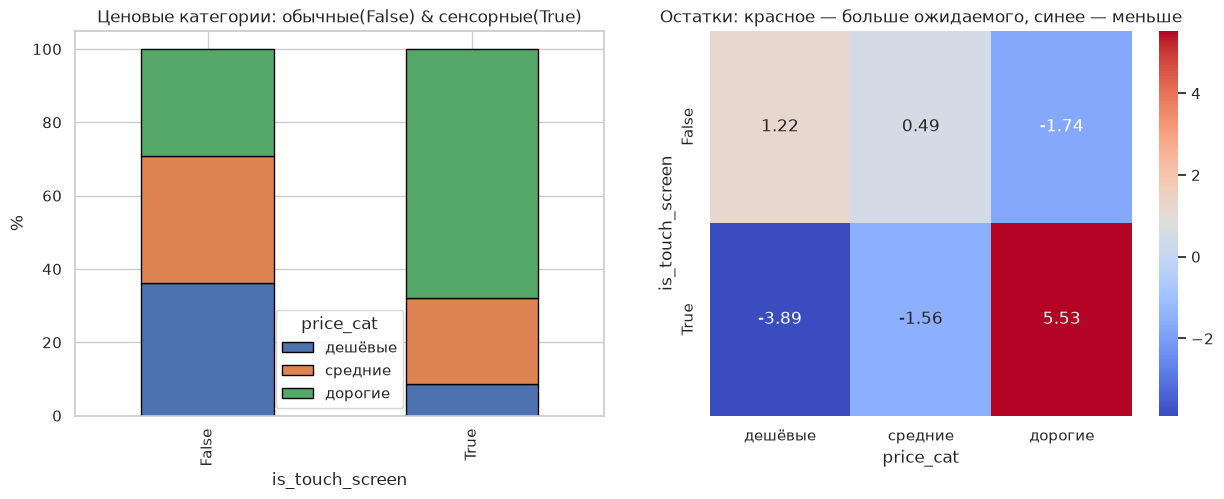

In [5]:

df["price_cat"] = pd.qcut(df["Price"], q=3, labels=["дешёвые", "средние", "дорогие"])
print("Границы категорий:")
print(df.groupby("price_cat", observed=True)["Price"].agg(["min", "max", "count"]))

d2 = df.dropna(subset=["is_touch_screen", "price_cat"])

table2 = pd.crosstab(d2["is_touch_screen"], d2['price_cat'])
print("\nНаблюдаемые количества:")
print(table2)
shares2 = pd.crosstab(d2["is_touch_screen"], d2["price_cat"], normalize="index") * 100
print("\nДоли внутри строки:")
print(shares2.round(2))

chi2, p, _, expected = stats.chi2_contingency(table2)
expected2 = pd.DataFrame(expected, index=table2.index, columns=table2.columns)
print("\nОжидаемые количества:")
print(expected2.round(1))
print("Минимальная ожидаемая частота:", round(expected.min(), 1))

print(f"\nx² = {chi2:.2f}, p-value = {p:.4}\n","H0 отвергается -> связь есть" if p < alpha else "H0 не отвергается -> связи не обнаружено")

n = table2.values.sum()
v2 = np.sqrt(chi2 / (n * (min(table2.shape) - 1)))
print(f"\nV Крамера = {v1:.3f}")
if v2 < 0.1: 
    print("Очень слабая связь")
elif v2 >= 0.1 and v2 < 0.3: 
    print("Слабая связь")
elif v2 >= 0.3 and v2 < 0.5:
    print("Средняя связь")
else:
    print("Сильная связь")

resid2 = (table2 - expected2) / np.sqrt(expected2)


fig, axes = plt.subplots(1, 2, figsize=(15, 5))
shares2.plot(kind="bar", stacked=True, ax=axes[0], edgecolor="black")
axes[0].set_ylabel("%")
axes[0].set_title("Ценовые категории: обычные(False) & сенсорные(True)")
sns.heatmap(resid2, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Остатки: красное — больше ожидаемого, синее — меньше")

plt.show()

- Среди сенсорных ноутбуков 68% - дорогие и только 9% - дешевые. Среди обычных ноутбуков категории разпределены почти поровну.
- Минимальная ожидаемая частота 26.5 > 5
- p-value < 0.05 => H0 отвергается: связь статистически значима.
- Однако V Крамера = 0.243 а значит связь слабая.
- По остаткам: сенсорных дорогих намного больше ожидаемого (55 вместо ≈ 27, остаток ≈ +5.5), а дешёвых — намного меньше (7 вместо ≈ 27, остаток ≈ −3.9).
- Вывод: сенсорный экран — «премиальная» функция, в бюджетных моделях почти не встречается.

### Задание 3. Парная корреляция

Проведите корреляционный анализ переменных (нужно рассмотреть не менее трёх разных пар переменных). Обоснуйте выбор рассчитываемых коэффициентов корреляции. Сформулируйте гипотезы. Визуализируйте наблюдаемые тенденции на подходящих графиках. Интерпретируйте результаты анализа (статистическая значимость, сила и направление взаимосвязи). Заполните таблицу (не менее 3 записей). 	 	 	 	 

| Анализируемые пары переменных | Выбранный коэффициент корреляции (обоснование выбора) | Гипотезы | Сила взаимосвязи | Направление взаимосвязи | Статистическая значимость взаимосвязи |
| --- | --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- | --- |


**Выбор коэффициента корреляции.** В задании 1 мы выяснили, что ни одна метрическая переменная не распределена нормально, есть выбросы (Price) и дискретные переменные (num_cores, ram_memory). Коэффициент Пирсона измеряет только *линейную* связь и предполагает нормальность, а выбросы его сильно искажают. Поэтому основной коэффициент — **ранговый коэффициент корреляции Спирмена**: он считает корреляцию не между значениями, а между их *рангами* (местами в упорядоченном ряду). Ему не нужна нормальность, он устойчив к выбросам и улавливает любую **монотонную** связь («больше одно — больше другое»), не обязательно линейную.

Для сравнения также посчитаем Пирсона и Кендалла (ещё один ранговый коэффициент, лучше работает при большом количестве одинаковых значений — «связок», как у num_cores и ram_memory), а для Спирмена — **95% доверительный интервал методом бутстрепа**.

- **H0**: кореляции между переменными нет
- **H1**: кореляция между переменными есть

**Шкала Чеддока для силы связи (по модулю):** 0.1–0.3 — слабая; 0.3–0.5 — умеренная; 0.5–0.7 — заметная; 0.7–0.9 — высокая; > 0.9 — весьма высокая.

Сначала посмотрим матрицу кореляций Спирмена для всех переменных

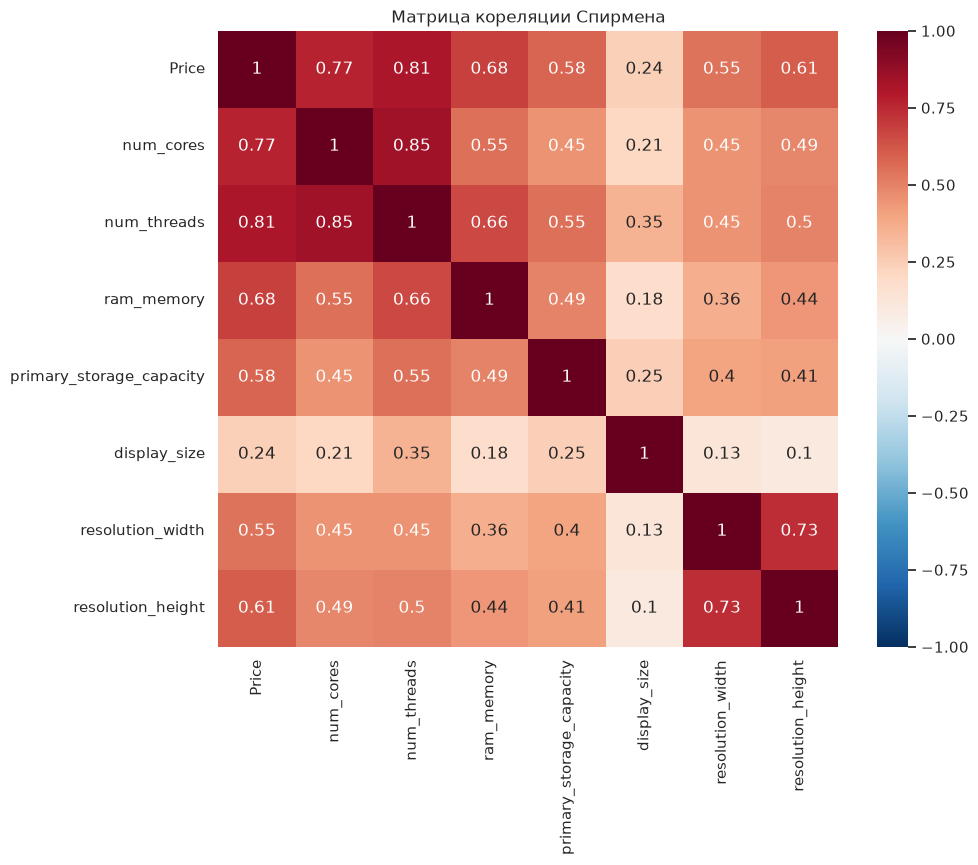

In [6]:
num_cols = ['Price', 'num_cores', 'num_threads', 'ram_memory', 'primary_storage_capacity', 
            'display_size', 'resolution_width', 'resolution_height']
corr = df[num_cols].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Матрица кореляции Спирмена")
plt.show()

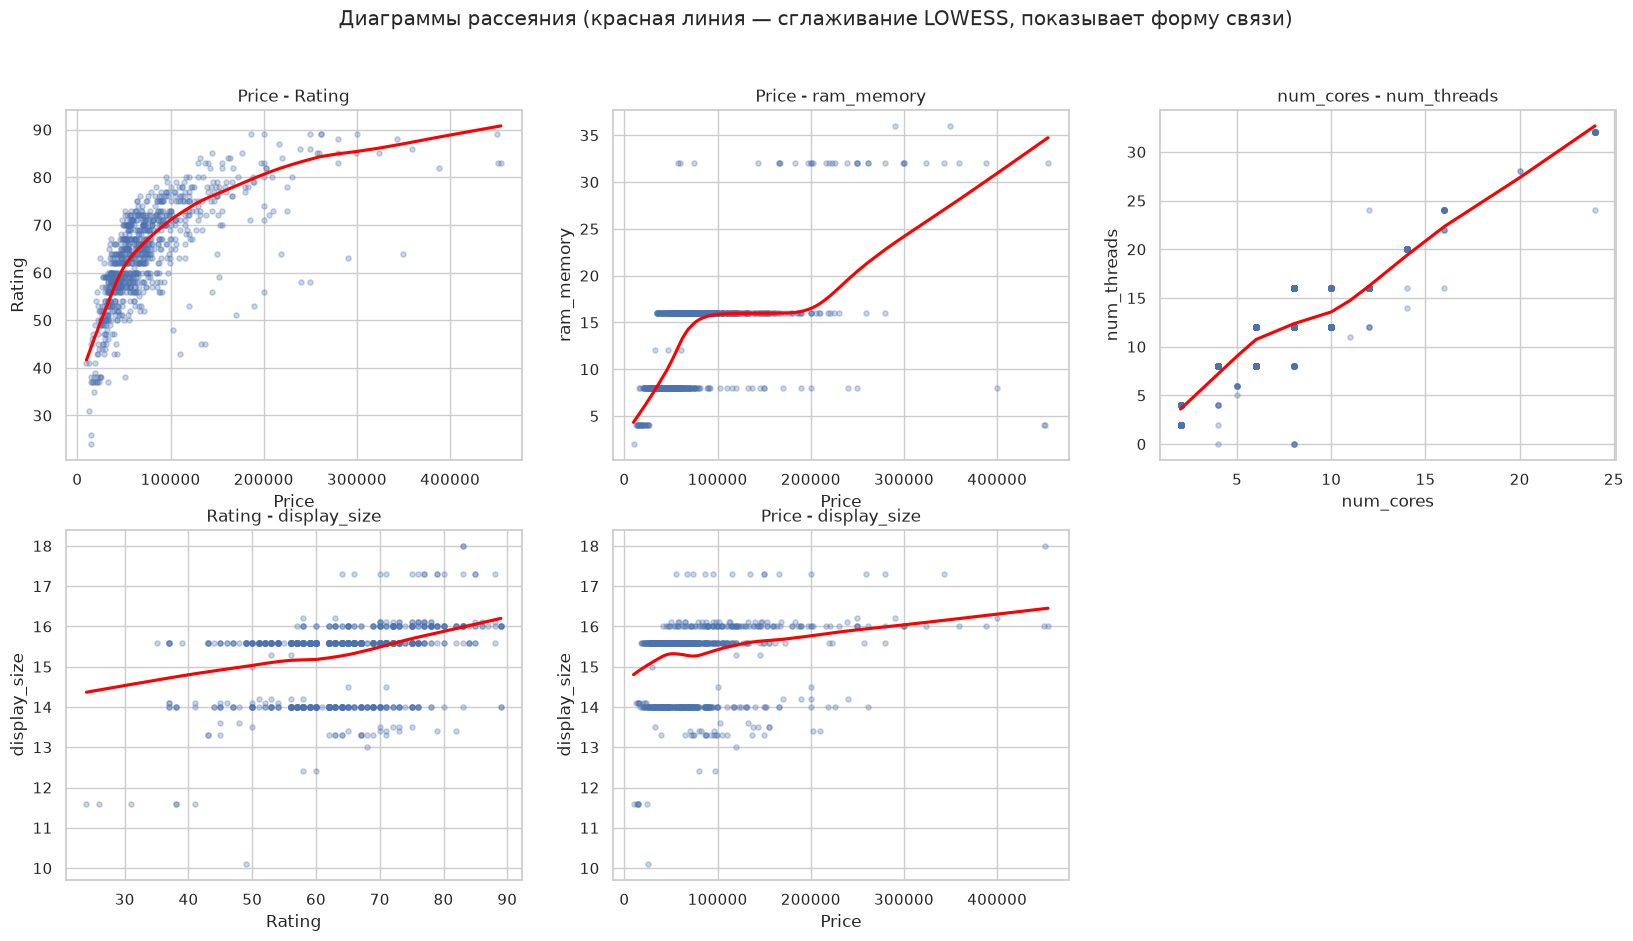

,n,ρ Спирмена,95% ДИ (бутстреп),p (Спирмен),r Пирсона,τ Кендалла,сила,направление,H0
пара,,,,,,,,,
Price – Rating,888,0.764012,[0.72; 0.80],8.608549e-171,0.659263,0.601178,высокая,прямая,отвергается
Price – ram_memory,895,0.680534,[0.64; 0.72],9.566265e-123,0.612126,0.568074,заметная,прямая,отвергается
num_cores – num_threads,920,0.850955,[0.83; 0.87],5.989783e-259,0.905952,0.773065,высокая,прямая,отвергается
Rating – display_size,890,0.378593,[0.32; 0.44],1.035750e-31,0.349601,0.296858,умеренная,прямая,отвергается
Price – display_size,897,0.242043,[0.17; 0.31],2.002761e-13,0.207328,0.185103,слабая,прямая,отвергается


In [7]:
rng = np.random.default_rng(42)
pairs = [("Price", "Rating"), ("Price", "ram_memory"), ("num_cores", "num_threads"),
         ("Rating", "display_size"), ("Price", "display_size")]

def bootstrap_spearman(x, y, n_b = 2000):
    n = len(x)
    boots = []
    for _ in range(n_b):
        idx = rng.integers(0, n, n)
        boots.append(stats.spearmanr(x[idx], y[idx])[0])
    return np.percentile(boots, [2.5, 97.5])

def chedock(r):
    a = abs(r)
    if a < 0.1: return "практически отсутствует"
    if a < 0.3: return "слабая"
    if a < 0.5: return "умеренная"
    if a < 0.7: return "заметная"
    if a < 0.9: return "высокая"
    return "весьма высокая"

rows = []
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, (a, b) in zip(axes.flat, pairs):
    s = df[[a, b]].dropna()
    x, y = s[a].values, s[b].values
    rho, p_s = stats.spearmanr(x, y)
    r_p, p_p = stats.pearsonr(x, y)
    tau, p_k = stats.kendalltau(x, y)
    lo, hi = bootstrap_spearman(x, y)
    rows.append({"пара": f"{a} – {b}", "n": len(s), "ρ Спирмена": rho, "95% ДИ (бутстреп)": f"[{lo:.2f}; {hi:.2f}]",
                     "p (Спирмен)": p_s, "r Пирсона": r_p, "τ Кендалла": tau,
                     "сила": chedock(rho), "направление": "прямая" if rho > 0 else "обратная",
                     "H0": "отвергается" if p_s < alpha else "не отвергается"})
    ax.scatter(x, y, s=14, alpha= 0.3)
    sns.regplot(x=x, y=y, ax=ax, scatter=False, lowess=True, color= "red")
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} - {b}")
axes.flat[-1].axis("off")
plt.suptitle("Диаграммы рассеяния (красная линия — сглаживание LOWESS, показывает форму связи)")
plt.show()
res3 = pd.DataFrame(rows).set_index("пара")
res3

1.**Price-Rating:** ρ Спирмена = 0.76 => связь высокая, прямая, значимая. Чем дороже ноутбук тем выше его рейтинг. Пирсон меньше (0.65) и это логично так как связь нелинейная (видно на графике).

2.**Price-ram_memory:** ρ Спирмена = 0.68 => связь заметная, прямая, значимая. Чем больше оперативной памяти тем больше цена.

3.**num_cores-num_threads:** ρ Спирмена = 0.85 => связь высокая, прямая, значимая. Пирсон больше (0.91), на графике видно что связь похожа на линейную.

4.**Rating – display_size:** ρ Спирмена = 0.38 => связь умеренная, прямая, значимая. Ноутбуки с большим экраном в среднем получают более высокий рейтинг. Пирсон (0.35), Кенделл (0.21) - тоже малы.

5.**Price – display_size:** ρ Спирмена = 0.24 => связь слабая, прямая, значимая. Размер экрана почти не влияет на цену (это кстати хорошо видно на диаграмме рассеивания, плотные скопления находятся на разных display_size и при этом диапозоны price у них почти совпадают). Пирсон и Кенделл соответственно тоже малы.

Во всех парах бутстреп-интервал не содержит 0 — это ещё одно подтверждение значимости.

### Задание 4. Частная корреляция
Посчитайте парный коэффициент корреляции между выбранной парой переменных. Посчитайте частный коэффициент корреляции между этими переменными, исключив влияние любой третьей переменной. Сделайте выводы. Визуализируйте наблюдаемые тенденции на подходящих графиках.

Рассмотрим пару Price-Rating(парная кореляция из 3 задания =0.76). Возможно, что часть этой связи объясняется объемом оперативной памяти (ram_memory): больше оперативы => больше цена.

### Как считаем: 
#### 1 способ:
Частная корреляция по формуле:

$$r_{xy \cdot z} = \frac{r_{xy} - r_{xz}\cdot r_{yz}}{\sqrt{(1 - r_{xz}^2)(1 - r_{yz}^2)}}$$

**Значимость** проверяем как у обычной корреляции, через t-статистику: t = r·√((n − 3) / (1 − r²)). Степеней свободы n − 3.

#### 2 способ:
Как считаем: переменные не нормальные => используем частную кореляцию Спирмена:
- переводим все три переменные в ранги
- строим линейную регрессию ранга Price на ранг ram_memory и берем остатки 
- то же самое для Rating
- кореляция между этими наборами остатков - частная кореляция

## Гипотезы:
**H0:** при контроле ram_memory связи между Price и Rating нет (ρ = 0)

**H1:** при контроле ram_memory связи между Price и Rating сохраняется (ρ != 0)

In [9]:
s4 = df[["Price", "Rating", "ram_memory"]].dropna()
n = len(s4)
print("Количество ноутбуков:", n)

r_xy, p_xy = stats.spearmanr(s4["Price"], s4["Rating"])
r_xz, _ = stats.spearmanr(s4["Price"], s4["ram_memory"])
r_yz, _ = stats.spearmanr(s4["Rating"], s4["ram_memory"])

print(f"Price – Rating: ρ = {r_xy:.3f}  (p = {p_xy:.1e})")
print(f"Price – ram_memory: ρ = {r_xz:.3f}")
print(f"Rating – ram_memory: ρ = {r_yz:.3f}")

Количество ноутбуков: 843
Price – Rating: ρ = 0.757  (p = 1.5e-157)
Price – ram_memory: ρ = 0.678
Rating – ram_memory: ρ = 0.654


Как можно заметить память сильно связана и с ценой, и с рейтингом (обе кореляции >0.65). Значит она действительно влияет на кореляцию.

#### 1 способ:

$$r_{xy \cdot z} = \frac{r_{xy} - r_{xz}\cdot r_{yz}}{\sqrt{(1 - r_{xz}^2)(1 - r_{yz}^2)}}$$


**Значимость** проверяем как у обычной корреляции, через t-статистику: t = r·√((n − 3) / (1 − r²)). Степеней свободы n − 3.

In [ ]:
r_part = (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz**2)*(1 - r_yz**2))

t = r_part * np.sqrt((n - 3)/(1 - r_part**2))
p_part = 2 * stats.t.sf(abs(t), n - 3)

print(f"Парная корреляция  Price – Rating: ρ = {r_xy:.3f}")
print(f"Частная корреляция Price – Rating (без влияния RAM): ρ = {r_part:.3f},  p-value = {p_part:.1e}")
print("H0", "отвергается => связь сохраняется и без влияния памяти" if p_part < alpha else "не отвергается")
print(f"\nСвязь ослабла на {(1 - r_part / r_xy) * 100:.0f}%")

Парная корреляция  Price – Rating: ρ = 0.757
Частная корреляция Price – Rating (без влияния RAM): ρ = 0.563,  p-value = 1.0e-71
H0 отвергается -> связь сохраняется и без влияния памяти

Связь ослабла на 26%


### 2 способ


In [12]:
rk = s4.rank()

a, b = np.polyfit(rk["ram_memory"], rk["Price"], 1)
rk["pred_Price"] = a * rk["ram_memory"] + b
rk["res_Price"]  = rk["Price"] - rk["pred_Price"]

# то же самое для рейтинга
a, b = np.polyfit(rk["ram_memory"], rk["Rating"], 1)
rk["pred_Rating"] = a * rk["ram_memory"] + b
rk["res_Rating"]  = rk["Rating"] - rk["pred_Rating"]

r_resid = np.corrcoef(rk["res_Price"], rk["res_Rating"])[0, 1]
print(f"Корреляция остатков = {r_resid:.3f} (по формуле было {r_part:.3f} — совпадает)")

Корреляция остатков = 0.563 (по формуле было 0.563 — совпадает)


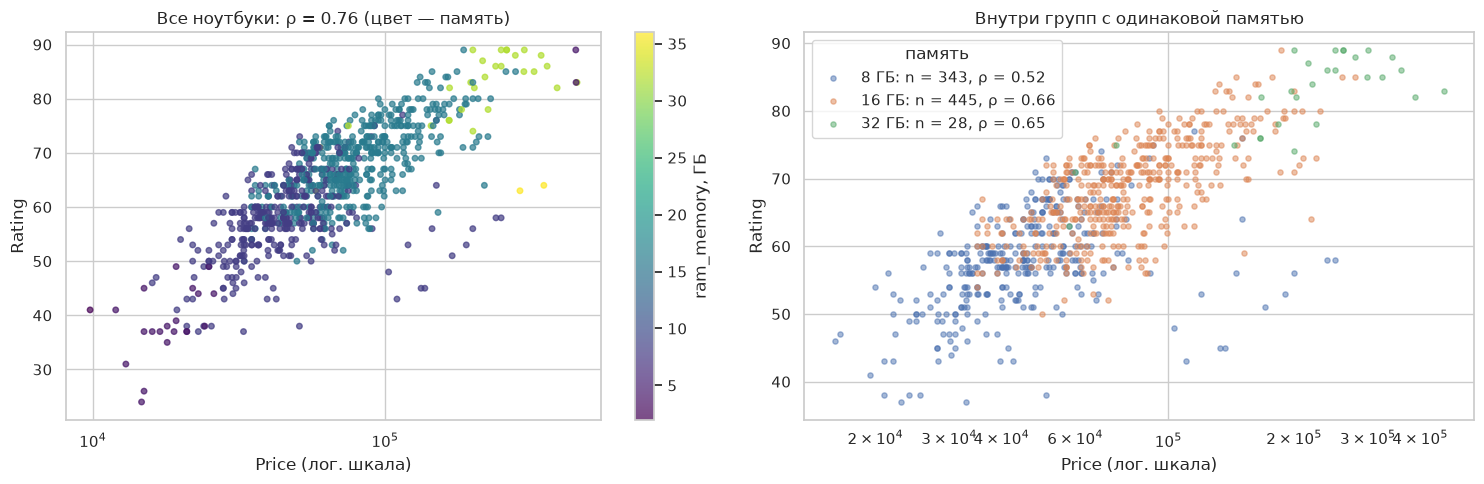

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Слева: все ноутбуки, цвет точки = объём памяти
sc = axes[0].scatter(s4["Price"], s4["Rating"], c=s4["ram_memory"], cmap="viridis", s=16, alpha=0.7)
plt.colorbar(sc, ax=axes[0], label="ram_memory, ГБ") # шкала цвета справа
axes[0].set_xscale("log")
axes[0].set_xlabel("Price (лог. шкала)")
axes[0].set_ylabel("Rating")
axes[0].set_title(f"Все ноутбуки: ρ = {r_xy:.2f} (цвет — память)")

# Справа: отдельно каждая группа с одинаковой памятью
for ram in [8, 16, 32]:
    g = s4[s4["ram_memory"] == ram] # ноутбуки только с этой памятью
    rho_g = stats.spearmanr(g["Price"], g["Rating"])[0] # корреляция внутри группы
    axes[1].scatter(g["Price"], g["Rating"], s=14, alpha=0.5,
                    label=f"{ram} ГБ: n = {len(g)}, ρ = {rho_g:.2f}")
axes[1].set_xscale("log")
axes[1].set_xlabel("Price (лог. шкала)")
axes[1].set_ylabel("Rating")
axes[1].set_title("Внутри групп с одинаковой памятью")
axes[1].legend(title="память")

plt.tight_layout()
plt.show()

- Левый график: видно, что цена и рейтинг сильно связаны (ρ = 0.76). Тёмные точки (мало памяти) собраны внизу слева, светлые (много памяти) вверху справа. Значит, память действительно «тянет» вверх и цену, и рейтинг.

- Правый график: память внутри каждой группы одинаковая, поэтому ничего объяснить не может. Связь всё равно есть (ρ ≈ 0.52–0.66), но она слабее общей. Это то же самое, что показала частная корреляция 0.56.

**Выводы по заданию 4.**

1. **Парная** корреляция цены и рейтинга: ρ ≈ **0.76**, это высокая связь.

2. Если убрать влияние оперативной памяти, **частная** корреляция ρ ≈ **0.56** (заметная связь), p-value намного меньше 0.05. **H0 отвергается:** цена и рейтинг связаны и при одинаковой памяти.

3. Связь **ослабла примерно на 26% (на четверть)**. Значит, **часть** связи действительно объясняется памятью: больше памяти → и дороже, и выше рейтинг. Но **бóльшая часть связи от памяти не зависит**. Её дают другие характеристики (процессор, видеокарта, экран), которые тоже одновременно повышают и цену, и рейтинг.

4. Это видно на графиках:
   - внутри групп с одинаковой памятью (8, 16, 32 ГБ) связь цены и рейтинга остаётся положительной, но она слабее общей (ρ ≈ 0.52 для 8 ГБ, ≈ 0.66 для 16 и 32 ГБ).

**Комментарии к заданию и принципам его оценивания:**

- Все пункты задания должны сопровождаться _выполненным_ фрагментом кода.
- Если Вы получили результаты в виде статистических показателей, таблиц или графиков, при этом никак их не прокомментировали и не сформулировали содержательные выводы на их основе, то работа оценивается в 0 баллов, в этом случае анализ данных не проведён.
- Если Вы полностью выполнили это задание, то получаете за него 8 баллов (отлично). Для получения более высокой оценки нужно выйти за рамки предложенного задания. В случае с текущим заданием это может быть дополнительное самостоятельное изучение методов оценки взаимосвязей между переменными и их применение для анализа данных, или развернутое и глубокое исследование имеющихся данных на основе использования пройденных на занятиях инструментов.
- В этом задании четыре пункта. Каждый из них весит 25%. 
- Задание можно выполнять индивидуально или в группе из 2 человек, критерии оценивания при этом не меняются;
- В названии загружаемого в Smart LMS файла нужно указать фамилию(ии) автора(ов) работы.
- В случае использования в работе ИИ необходимо указать где и как именно он использовался.

### Этот файл нужно сохранить как Jupyter Notebook (.ipynb) и загрузить в Smart LMS до 23:55 18 октября.